In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from scipy import stats
from sklearn.preprocessing import StandardScaler

In [3]:
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path)

In [4]:
df

,datetime,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
0,2022-01-01 00:00:00,46.4,78.6,34.8,17.8,42.4,13.8,25.95,0,23.31,0.41,83.18,3.18
1,2022-01-01 01:00:00,53.8,82.8,33.6,17.0,45.0,14.2,26.25,0,23.31,0.00,83.38,3.12
2,2022-01-01 02:00:00,58.0,89.4,24.4,15.8,33.8,18.0,28.56,0,23.45,0.00,83.97,3.10
3,2022-01-01 03:00:00,59.2,94.8,24.0,17.4,37.2,18.6,29.12,0,23.33,0.00,84.78,3.12
4,2022-01-01 04:00:00,53.4,82.0,26.4,17.6,48.2,15.2,29.83,0,23.13,0.00,85.51,3.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...
26299,2024-12-31 19:00:00,23.2,29.0,13.0,4.0,29.0,4.0,26.00,0,23.59,0.00,85.09,3.06
26300,2024-12-31 20:00:00,23.4,30.0,14.0,4.0,29.0,4.0,25.56,0,23.40,0.03,85.41,3.13
26301,2024-12-31 21:00:00,19.2,31.0,13.0,4.0,29.0,4.0,25.47,0,23.42,0.16,86.31,3.29
26302,2024-12-31 22:00:00,19.2,32.0,13.0,4.0,29.0,4.0,25.62,0,23.57,0.21,87.68,3.41


In [5]:
df.dtypes

,0
datetime,datetime64[ns]
PM10,float64
PM2.5,float64
SO2,float64
CO,float64
O3,float64
NO2,float64
Suhu Udara,float64
Radiasi Matahari,int64
Suhu Titik Embun,float64


In [6]:
df.isnull()

,datetime,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
26299,False,False,False,False,False,False,False,False,False,False,False,False,False
26300,False,False,False,False,False,False,False,False,False,False,False,False,False
26301,False,False,False,False,False,False,False,False,False,False,False,False,False
26302,False,False,False,False,False,False,False,False,False,False,False,False,False


In [7]:
df.isnull().sum()

,0
datetime,0
PM10,0
PM2.5,0
SO2,0
CO,0
O3,0
NO2,0
Suhu Udara,0
Radiasi Matahari,0
Suhu Titik Embun,0


In [8]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df_ts = df.set_index('datetime')
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

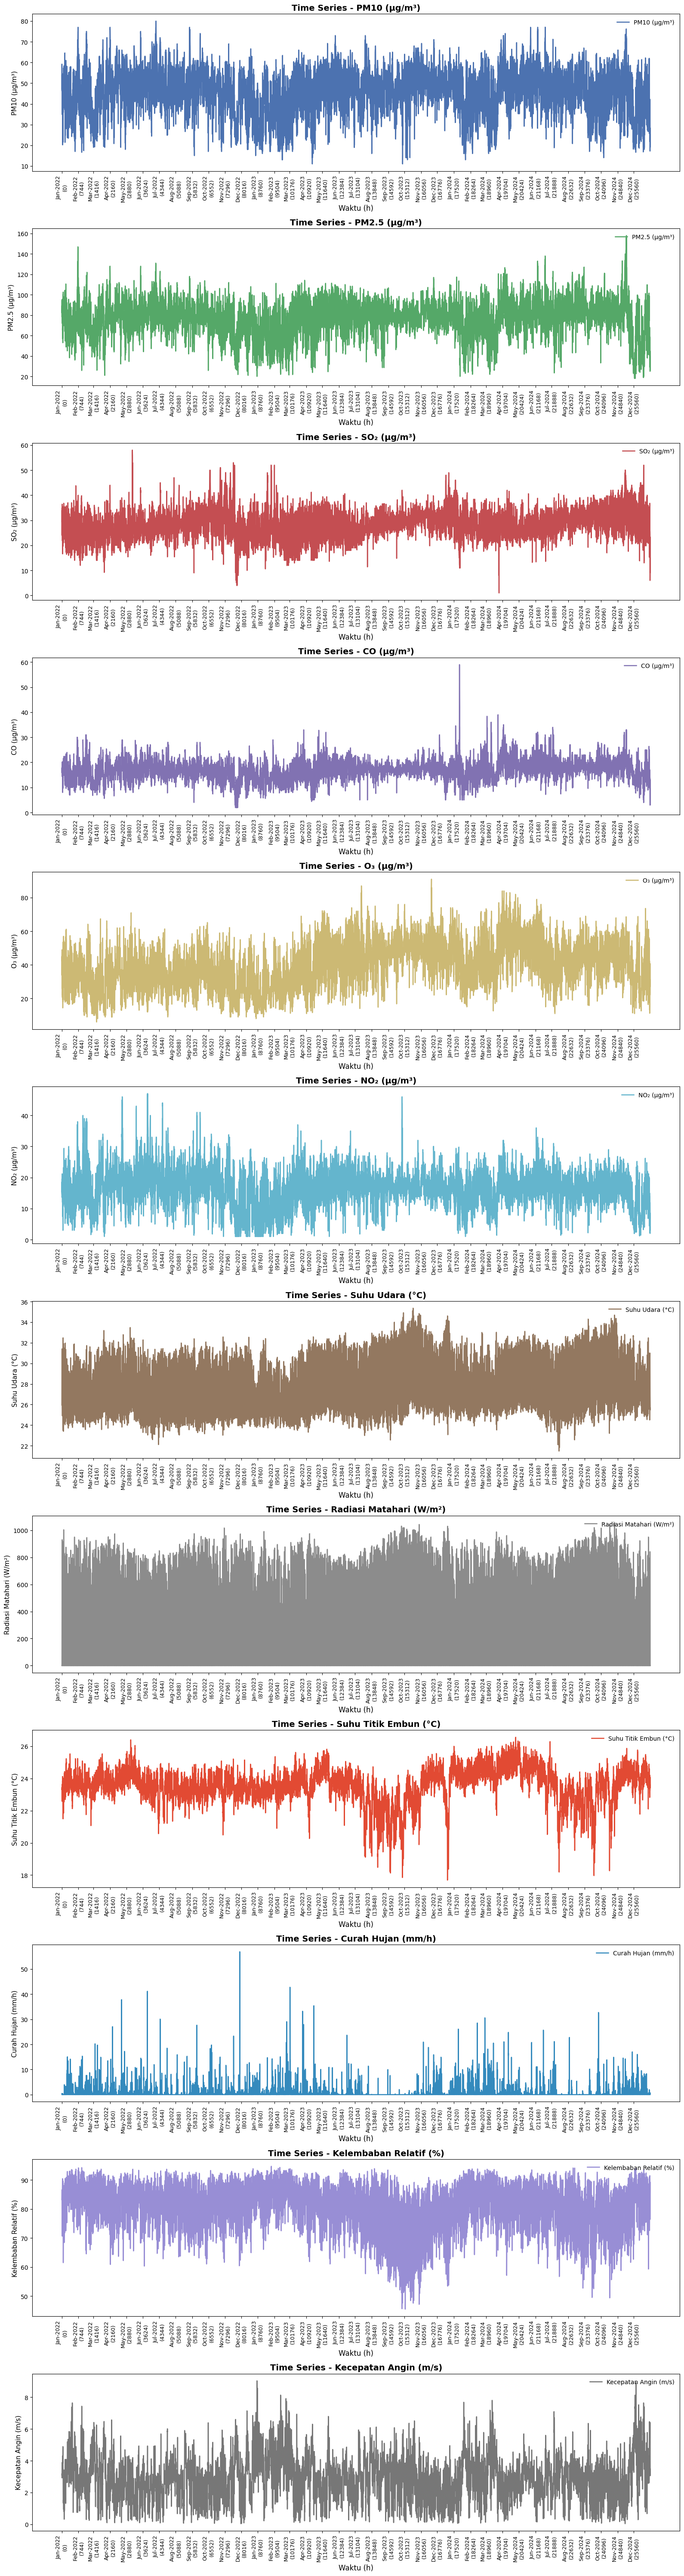

In [9]:
if not isinstance(df_ts.index, pd.DatetimeIndex):
    df_ts.index = pd.to_datetime(df_ts.index)
df_ts = df_ts.sort_index()

hours = (df_ts.index - df_ts.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_ts.index.min().normalize(),
                       end=df_ts.index.max().normalize(), freq="MS")
xticks_hours = (xticks - df_ts.index.min()) / pd.Timedelta(hours=1)
labels = [f"{d.strftime('%b-%Y')}\n({int(h)})" for d, h in zip(xticks, xticks_hours)]

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_ts.columns) > len(colors):
    colors = (colors * (len(df_ts.columns) // len(colors) + 1))[:len(df_ts.columns)]

label_map = {
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (µg/m³)',
    'O3': 'O₃ (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'Suhu Udara': 'Suhu Udara (°C)',
    'Radiasi Matahari': 'Radiasi Matahari (W/m²)',
    'Suhu Titik Embun': 'Suhu Titik Embun (°C)',
    'Curah Hujan': 'Curah Hujan (mm/h)',
    'Kelembaban Relatif': 'Kelembaban Relatif (%)',
    'Kecepatan Angin': 'Kecepatan Angin (m/s)',
}

fig, axes = plt.subplots(
    nrows=len(df_ts.columns),
    figsize=(16, 5 * len(df_ts.columns)),
    sharex=False
)

if len(df_ts.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_ts.columns, colors):
    ax.plot(hours, df_ts[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu (h)", fontsize=12)

plt.tight_layout()
plt.show()

In [10]:
df_ts.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
count,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00
mean,45.92,76.14,28.24,16.82,39.96,16.33,27.52,219.17,23.52,0.60,81.46,2.86
std,11.70,18.51,6.49,4.44,14.69,6.58,2.42,292.02,1.05,2.08,8.34,1.27
min,11.00,18.00,1.00,2.00,6.00,1.00,21.48,0.00,17.69,0.00,45.50,0.04
25%,38.80,66.00,24.00,14.00,28.60,12.80,25.51,0.00,23.03,0.00,76.45,1.96
50%,48.00,78.00,28.00,17.00,40.00,17.00,27.01,13.00,23.63,0.00,83.42,2.77
75%,54.00,87.40,32.20,19.20,51.00,20.00,29.40,443.00,24.20,0.20,88.02,3.63
max,80.00,158.00,58.00,59.00,91.00,47.00,35.36,1056.00,26.55,56.89,94.68,9.03


In [11]:
df.replace(['-', ''], np.nan, inplace=True)

for col in df.columns:
    if col != 'datetime':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df_numeric = df.drop(columns=["datetime"])
datetime_col = df["datetime"]

In [13]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)

In [14]:
imputer = KNNImputer(n_neighbors=5)
df_scaled_imputed = imputer.fit_transform(df_scaled)

df_imputed = pd.DataFrame(scaler.inverse_transform(df_scaled_imputed), columns=df_numeric.columns)
df_imputed["datetime"] = datetime_col
df_imputed = df_imputed.set_index("datetime")

In [15]:
df_imputed.head(10)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
datetime,,,,,,,,,,,,
2022-01-01 00:00:00,46.4,78.6,34.8,17.8,42.4,13.8,25.95,0.0,23.31,0.41,83.18,3.18
2022-01-01 01:00:00,53.8,82.8,33.6,17.0,45.0,14.2,26.25,0.0,23.31,0.00,83.38,3.12
2022-01-01 02:00:00,58.0,89.4,24.4,15.8,33.8,18.0,28.56,0.0,23.45,0.00,83.97,3.10
2022-01-01 03:00:00,59.2,94.8,24.0,17.4,37.2,18.6,29.12,0.0,23.33,0.00,84.78,3.12
2022-01-01 04:00:00,53.4,82.0,26.4,17.6,48.2,15.2,29.83,0.0,23.13,0.00,85.51,3.12
2022-01-01 05:00:00,58.2,84.2,27.8,17.6,41.4,19.6,30.81,0.0,22.75,0.05,86.35,3.07
2022-01-01 06:00:00,46.8,89.4,34.0,17.8,49.0,14.6,31.12,82.0,22.63,0.00,86.57,2.92
2022-01-01 07:00:00,54.2,82.8,29.2,15.8,25.8,15.4,31.41,259.0,22.58,0.00,84.37,3.14
2022-01-01 08:00:00,51.6,84.2,29.2,16.4,46.0,16.8,30.73,371.0,22.80,0.00,80.24,3.36


In [16]:
df_imputed.to_csv("df_imputed.csv", index=False, float_format='%.2f')

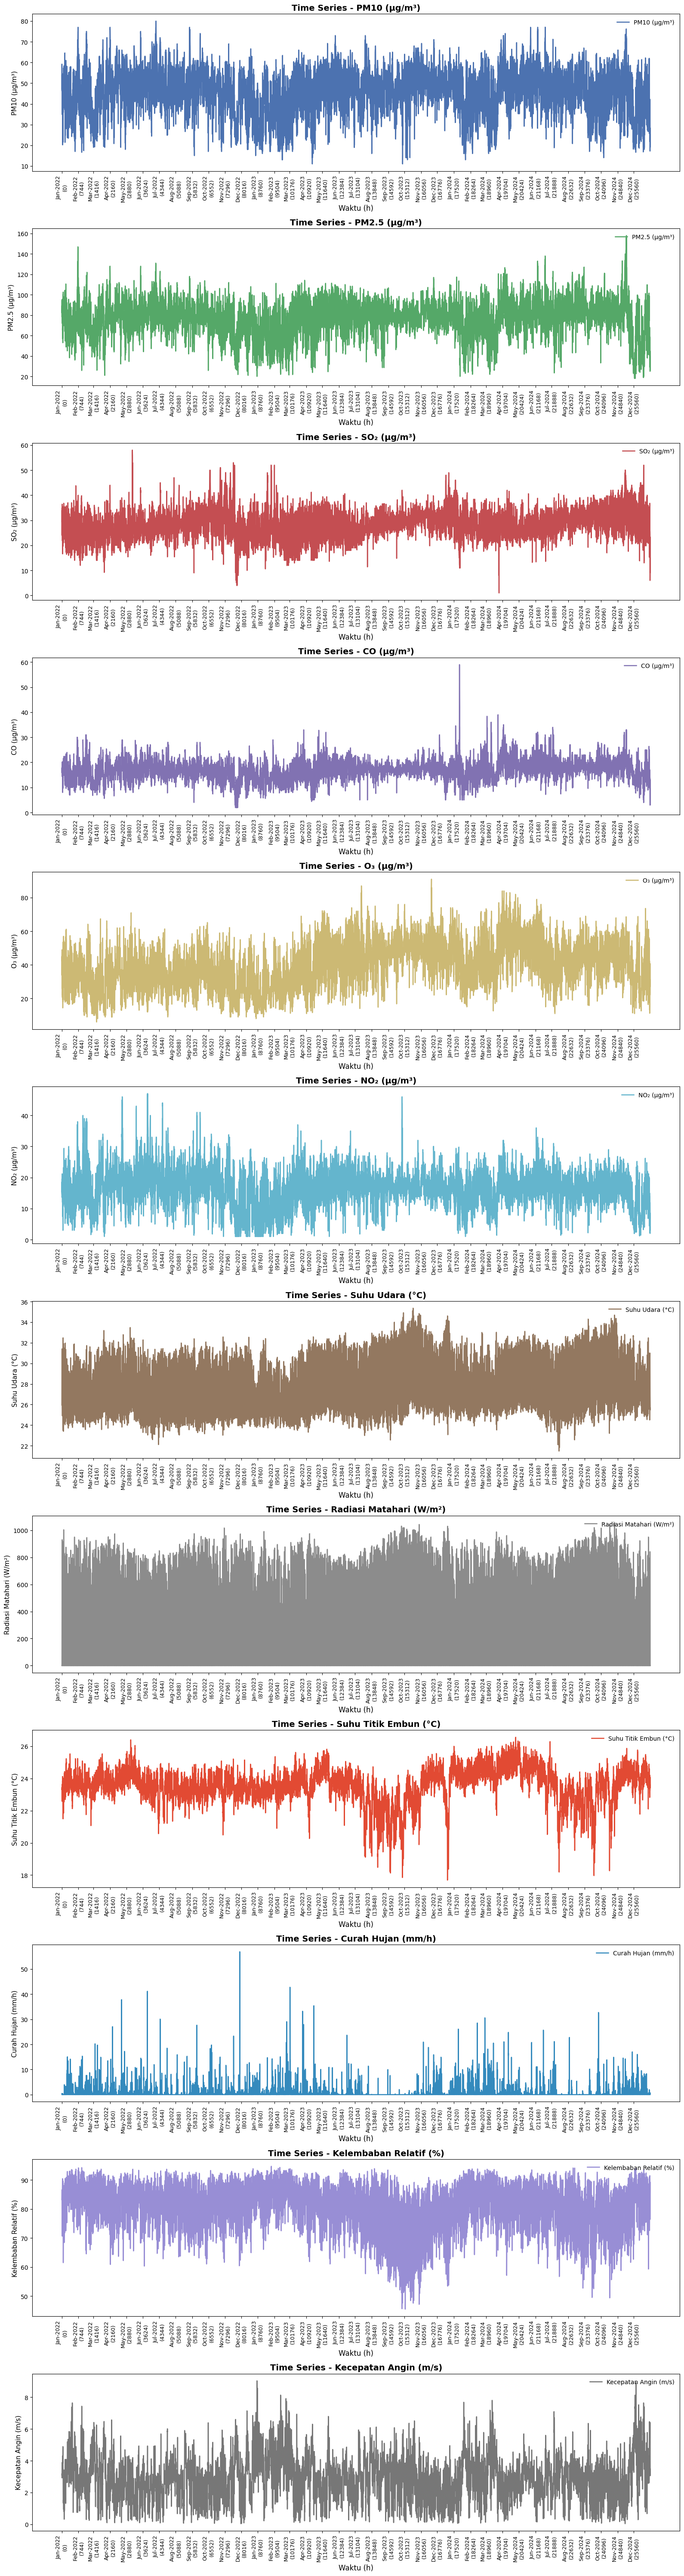

In [17]:
if not isinstance(df_imputed.index, pd.DatetimeIndex):
    df_imputed.index = pd.to_datetime(df_imputed.index)
df_imputed = df_imputed.sort_index()

hours = (df_imputed.index - df_imputed.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_imputed.index.min().normalize(),
                       end=df_imputed.index.max().normalize(), freq="MS")
xticks_hours = (xticks - df_imputed.index.min()) / pd.Timedelta(hours=1)
labels = [f"{d.strftime('%b-%Y')}\n({int(h)})" for d, h in zip(xticks, xticks_hours)]

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_imputed.columns) > len(colors):
    colors = (colors * (len(df_imputed.columns) // len(colors) + 1))[:len(df_imputed.columns)]

label_map = {
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (µg/m³)',
    'O3': 'O₃ (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'Suhu Udara': 'Suhu Udara (°C)',
    'Radiasi Matahari': 'Radiasi Matahari (W/m²)',
    'Suhu Titik Embun': 'Suhu Titik Embun (°C)',
    'Curah Hujan': 'Curah Hujan (mm/h)',
    'Kelembaban Relatif': 'Kelembaban Relatif (%)',
    'Kecepatan Angin': 'Kecepatan Angin (m/s)',
}

fig, axes = plt.subplots(
    nrows=len(df_imputed.columns),
    figsize=(16, 5 * len(df_imputed.columns)),
    sharex=False
)

if len(df_imputed.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_imputed.columns, colors):
    ax.plot(hours, df_imputed[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu (h)", fontsize=12)

plt.tight_layout()
plt.show()

In [18]:
df_imputed.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
count,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00
mean,45.92,76.14,28.24,16.82,39.96,16.33,27.52,219.17,23.52,0.60,81.46,2.86
std,11.70,18.51,6.49,4.44,14.69,6.58,2.42,292.02,1.05,2.08,8.34,1.27
min,11.00,18.00,1.00,2.00,6.00,1.00,21.48,0.00,17.69,0.00,45.50,0.04
25%,38.80,66.00,24.00,14.00,28.60,12.80,25.51,0.00,23.03,0.00,76.45,1.96
50%,48.00,78.00,28.00,17.00,40.00,17.00,27.01,13.00,23.63,0.00,83.42,2.77
75%,54.00,87.40,32.20,19.20,51.00,20.00,29.40,443.00,24.20,0.20,88.02,3.63
max,80.00,158.00,58.00,59.00,91.00,47.00,35.36,1056.00,26.55,56.89,94.68,9.03


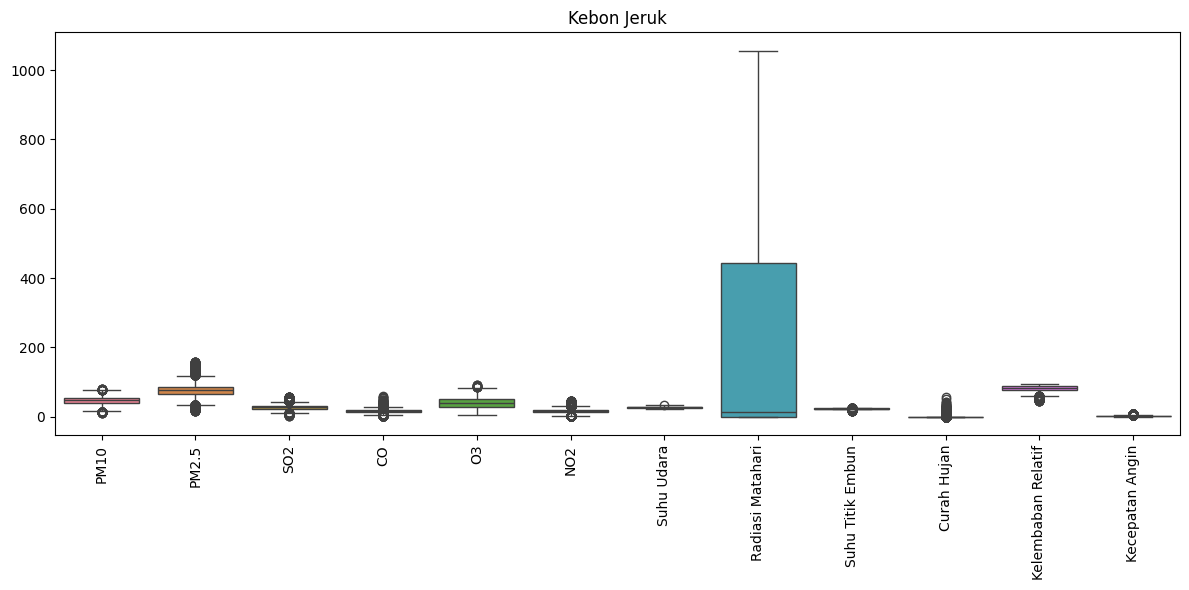

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_imputed)
plt.xticks(rotation=90)
plt.title("Kebon Jeruk")
plt.tight_layout()
plt.show()